# Hospital Data Analysis & Machine Learning Predictive Pipeline

This notebook provides a complete, production-grade end-to-end workflow:
1. **Data Ingestion & Quality Audit**: Missingness, duplication, schema verification
2. **Data Cleaning & Preprocessing**: Type standardizations, whitespace trimming
3. **Feature Engineering**: Risk indicators, unit costs (`Cost_per_Day`), demographic & stay duration bins
4. **Exploratory Data Analysis (EDA)**: Visualizations, correlation matrices, and clinical cohort analysis
5. **Predictive Modeling Track 1 - Readmission Prediction**:
   - Target: `Readmission_Flag` (Binary Classification)
   - Algorithms: **Logistic Regression**, **Random Forest**, **Gradient Boosting**
   - Metrics: ROC-AUC, Precision, Recall, F1-Score, Confusion Matrices, Feature Importance
6. **Predictive Modeling Track 2 - Patient Satisfaction Prediction**:
   - Target: `Satisfaction` (Regression & Multiclass Classification)
   - Algorithms: **Ridge Regression**, **Random Forest Regressor / Classifier**
   - Metrics: $R^2$, RMSE, MAE, Accuracy, Confusion Matrix
7. **Actionable Healthcare Insights**: Clinical findings and operational recommendations.

--- 
## 1. Environment Setup & Library Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Machine Learning libraries
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, RandomForestRegressor
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, roc_curve,
    mean_squared_error, mean_absolute_error, r2_score, accuracy_score
)

# Visual style setup
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.figsize"] = (10, 6)
%matplotlib inline
print("Libraries successfully imported.")

Libraries successfully imported.


--- 
## 2. Data Loading & Quality Auditing

In [3]:
raw_path = 'hospital data analysis.csv'
df_raw = pd.read_csv(raw_path)
print(f"Raw records: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
df_raw.head()

Raw records: 984 rows, 10 columns


,Patient_ID,Age,Gender,Condition,Procedure,Cost,Length_of_Stay,Readmission,Outcome,Satisfaction
0,1,45,Female,Heart Disease,Angioplasty,15000,5,No,Recovered,4
1,2,60,Male,Diabetes,Insulin Therapy,2000,3,Yes,Stable,3
2,3,32,Female,Fractured Arm,X-Ray and Splint,500,1,No,Recovered,5
3,4,75,Male,Stroke,CT Scan and Medication,10000,7,Yes,Stable,2
4,5,50,Female,Cancer,Surgery and Chemotherapy,25000,10,No,Recovered,4


In [4]:
# Checking completeness and duplication
print("--- Missing Values ---")
print(df_raw.isnull().sum())
print(f"\nFull Duplicates: {df_raw.duplicated().sum()}")
print(f"Patient_ID Duplicates: {df_raw.duplicated(subset=['Patient_ID']).sum()}")

--- Missing Values ---
Patient_ID        0
Age               0
Gender            0
Condition         0
Procedure         0
Cost              0
Length_of_Stay    0
Readmission       0
Outcome           0
Satisfaction      0
dtype: int64

Full Duplicates: 0
Patient_ID Duplicates: 0


--- 
## 3. Data Cleaning, Type Standardization & Feature Engineering

In [5]:
df = df_raw.copy()

# 1. Trim strings
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].astype(str).str.strip()

# 2. Enforce exact integer types
num_cols = ['Patient_ID', 'Age', 'Cost', 'Length_of_Stay', 'Satisfaction']
for col in num_cols:
    df[col] = df[col].astype(int)

# 3. Binary encodings
df['Readmission_Flag'] = df['Readmission'].map({'Yes': 1, 'No': 0}).astype(int)
df['Outcome_Recovered'] = df['Outcome'].map({'Recovered': 1, 'Stable': 0}).astype(int)

# 4. Engineered metrics
df['Cost_per_Day'] = (df['Cost'] / df['Length_of_Stay']).round(2)

# 5. Demographic and stay groupings
df['Age_Group'] = pd.cut(df['Age'], bins=[0, 39, 59, 120], labels=['Young Adult (<40)', 'Middle-Aged (40-59)', 'Senior (60+)'])
df['LOS_Category'] = pd.cut(df['Length_of_Stay'], bins=[0, 7, 30, 365], labels=['Short Stay (1-7d)', 'Medium Stay (8-30d)', 'Long Stay (31+d)'])

# Save clean snapshot
df.to_csv('hospital_data_cleaned.csv', index=False)
print(f"Cleaned dataset prepared: {df.shape[0]} rows x {df.shape[1]} columns.")
df.head()

Cleaned dataset prepared: 984 rows x 15 columns.


,Patient_ID,Age,Gender,Condition,Procedure,Cost,Length_of_Stay,Readmission,Outcome,Satisfaction,Readmission_Flag,Outcome_Recovered,Cost_per_Day,Age_Group,LOS_Category
0,1,45,Female,Heart Disease,Angioplasty,15000,5,No,Recovered,4,0,1,3000.00,Middle-Aged (40-59),Short Stay (1-7d)
1,2,60,Male,Diabetes,Insulin Therapy,2000,3,Yes,Stable,3,1,0,666.67,Senior (60+),Short Stay (1-7d)
2,3,32,Female,Fractured Arm,X-Ray and Splint,500,1,No,Recovered,5,0,1,500.00,Young Adult (<40),Short Stay (1-7d)
3,4,75,Male,Stroke,CT Scan and Medication,10000,7,Yes,Stable,2,1,0,1428.57,Senior (60+),Short Stay (1-7d)
4,5,50,Female,Cancer,Surgery and Chemotherapy,25000,10,No,Recovered,4,0,1,2500.00,Middle-Aged (40-59),Medium Stay (8-30d)


--- 
## 4. Exploratory Data Analysis (EDA)

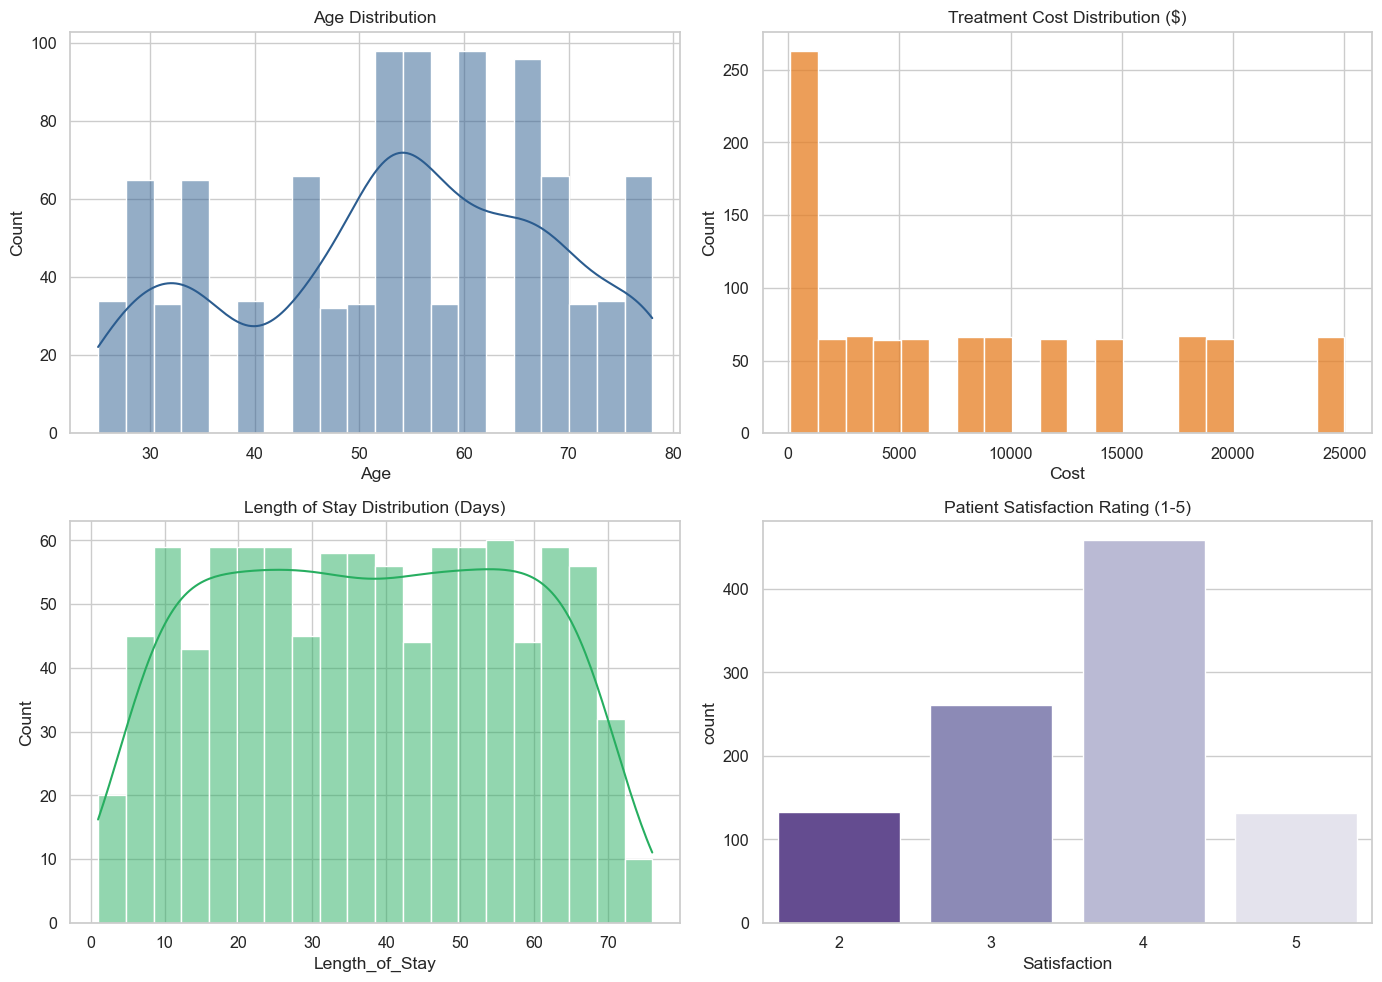

In [6]:
# Visualizing distributions of numeric variables
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df['Age'], kde=True, ax=axes[0, 0], color='#2b5c8f', bins=20)
axes[0, 0].set_title('Age Distribution')

sns.histplot(df['Cost'], kde=False, ax=axes[0, 1], color='#e67e22', bins=20)
axes[0, 1].set_title('Treatment Cost Distribution ($)')

sns.histplot(df['Length_of_Stay'], kde=True, ax=axes[1, 0], color='#27ae60', bins=20)
axes[1, 0].set_title('Length of Stay Distribution (Days)')

sns.countplot(x='Satisfaction', data=df, ax=axes[1, 1], palette='Purples_r')
axes[1, 1].set_title('Patient Satisfaction Rating (1-5)')

plt.tight_layout()
plt.show()

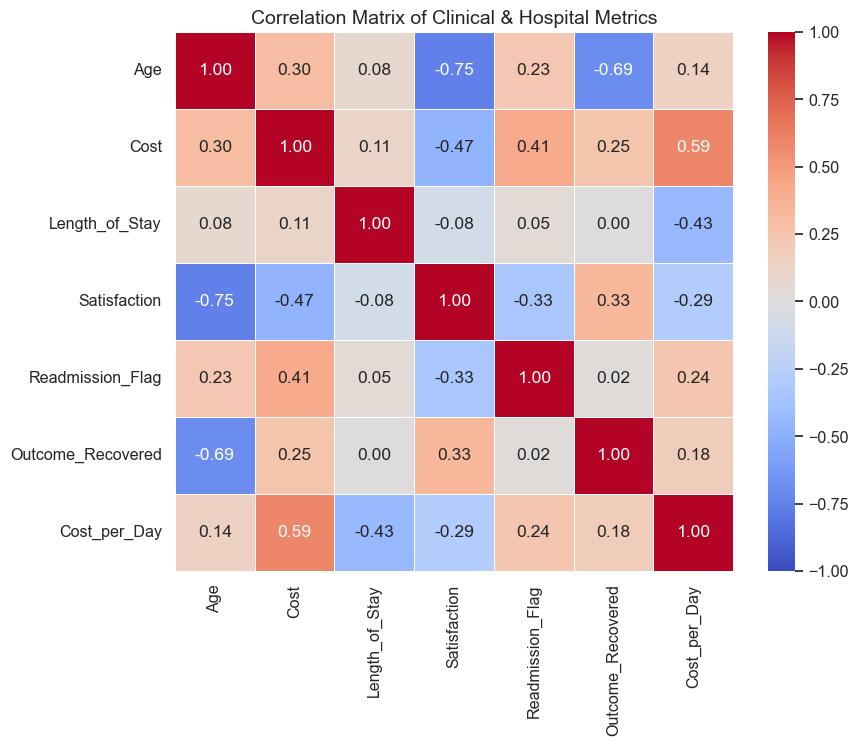

In [7]:
# Correlation Heatmap of Numeric Features
corr_cols = ['Age', 'Cost', 'Length_of_Stay', 'Satisfaction', 'Readmission_Flag', 'Outcome_Recovered', 'Cost_per_Day']
plt.figure(figsize=(9, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Matrix of Clinical & Hospital Metrics', fontsize=14)
plt.show()

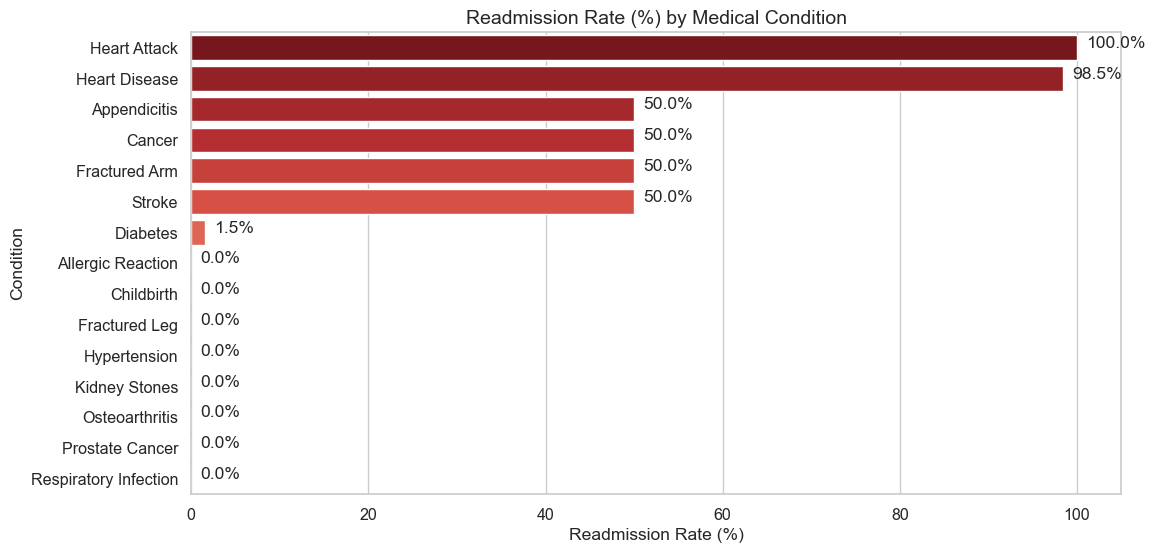

In [8]:
# Readmission Rate across Medical Conditions
readmit_rates = df.groupby('Condition')['Readmission_Flag'].mean().sort_values(ascending=False) * 100

plt.figure(figsize=(12, 6))
sns.barplot(x=readmit_rates.values, y=readmit_rates.index, palette='Reds_r')
plt.title('Readmission Rate (%) by Medical Condition', fontsize=14)
plt.xlabel('Readmission Rate (%)')
plt.ylabel('Condition')
plt.xlim(0, 105)
for i, v in enumerate(readmit_rates.values):
    plt.text(v + 1, i, f"{v:.1f}%")
plt.show()

--- 
## 5. Machine Learning Track 1: Predicting Hospital Readmission

**Objective**: Build a predictive model to identify patients at high risk of readmission upon admission or treatment, enabling timely intervention.

Features used:
- Numerical: `Age`, `Cost`, `Length_of_Stay`
- Categorical: `Gender`, `Condition`, `Outcome`
- Target: `Readmission_Flag` (Binary: 0 = No, 1 = Yes)

In [9]:
# Features and Target Split
X_readmit = df[['Age', 'Cost', 'Length_of_Stay', 'Gender', 'Condition', 'Outcome']]
y_readmit = df['Readmission_Flag']

num_features_r = ['Age', 'Cost', 'Length_of_Stay']
cat_features_r = ['Gender', 'Condition', 'Outcome']

# Preprocessor with scaling and one-hot encoding
preprocessor_readmit = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features_r),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_features_r)
    ]
)

# Stratified 80/20 Train-Test Split
X_train_rd, X_test_rd, y_train_rd, y_test_rd = train_test_split(
    X_readmit, y_readmit, test_size=0.20, random_state=42, stratify=y_readmit
)

print(f"Training set: {X_train_rd.shape[0]} samples")
print(f"Testing set:  {X_test_rd.shape[0]} samples")

Training set: 787 samples
Testing set:  197 samples



==================== Logistic Regression ====================
Accuracy: 0.8629 | ROC-AUC: 0.9539
              precision    recall  f1-score   support

           0     0.9149    0.8958    0.9053       144
           1     0.7321    0.7736    0.7523        53

    accuracy                         0.8629       197
   macro avg     0.8235    0.8347    0.8288       197
weighted avg     0.8657    0.8629    0.8641       197


==================== Random Forest ====================
Accuracy: 0.9898 | ROC-AUC: 0.9959
              precision    recall  f1-score   support

           0     0.9931    0.9931    0.9931       144
           1     0.9811    0.9811    0.9811        53

    accuracy                         0.9898       197
   macro avg     0.9871    0.9871    0.9871       197
weighted avg     0.9898    0.9898    0.9898       197


==================== Gradient Boosting ====================
Accuracy: 0.9898 | ROC-AUC: 0.9846
              precision    recall  f1-score   support

     

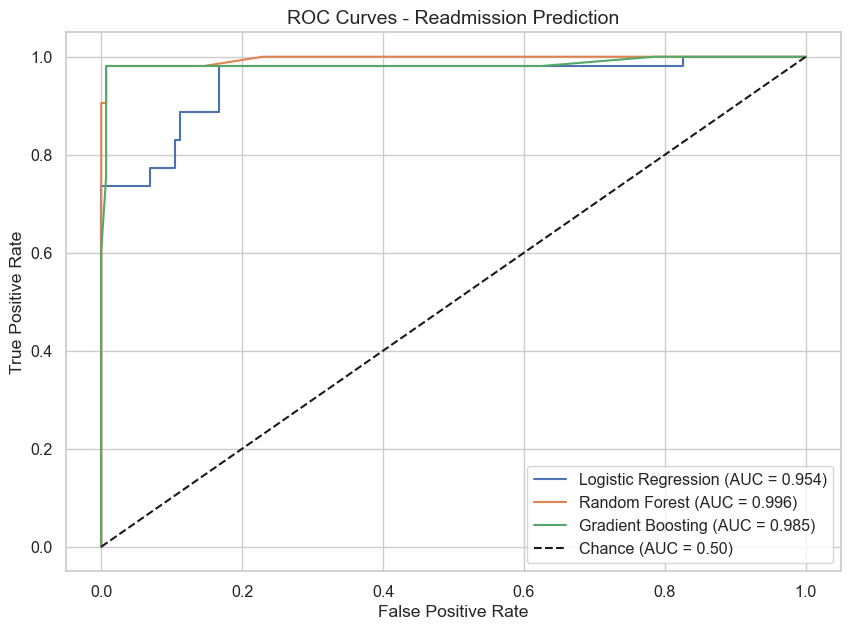

In [10]:
# Define Models
classifiers = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42)
}

results_clf = {}
plt.figure(figsize=(10, 7))

for name, clf in classifiers.items():
    pipeline = Pipeline(steps=[('prep', preprocessor_readmit), ('model', clf)])
    pipeline.fit(X_train_rd, y_train_rd)
    
    y_pred = pipeline.predict(X_test_rd)
    y_proba = pipeline.predict_proba(X_test_rd)[:, 1]
    
    acc = accuracy_score(y_test_rd, y_pred)
    auc = roc_auc_score(y_test_rd, y_proba)
    results_clf[name] = {'Pipeline': pipeline, 'Accuracy': acc, 'ROC-AUC': auc, 'Predictions': y_pred}
    
    print(f"\n==================== {name} ====================")
    print(f"Accuracy: {acc:.4f} | ROC-AUC: {auc:.4f}")
    print(classification_report(y_test_rd, y_pred, digits=4))
    
    # Plot ROC curve
    fpr, tpr, _ = roc_curve(y_test_rd, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Chance (AUC = 0.50)')
plt.title('ROC Curves - Readmission Prediction', fontsize=14)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.show()

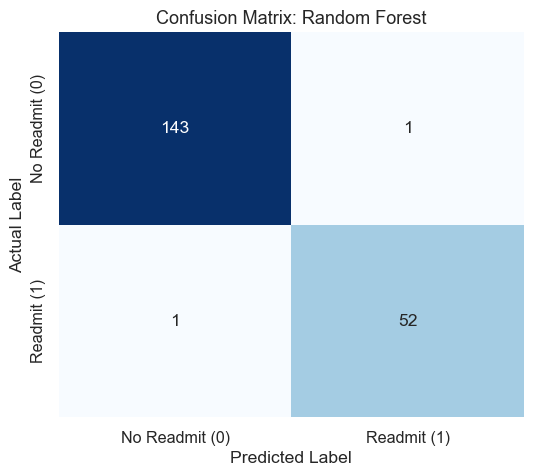

In [11]:
# Confusion Matrix for the Best Classifier (Random Forest)
best_clf_name = 'Random Forest'
cm = confusion_matrix(y_test_rd, results_clf[best_clf_name]['Predictions'])

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Readmit (0)', 'Readmit (1)'],
            yticklabels=['No Readmit (0)', 'Readmit (1)'])
plt.title(f'Confusion Matrix: {best_clf_name}', fontsize=13)
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

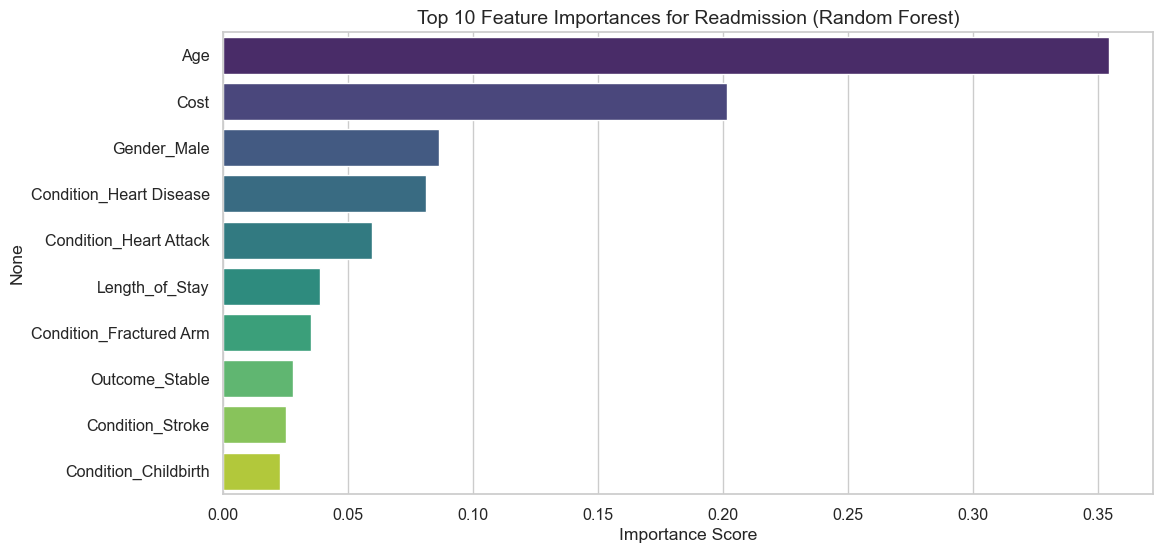

In [12]:
# Feature Importance for Readmission (Random Forest)
rf_model = results_clf['Random Forest']['Pipeline'].named_steps['model']
prep_step = results_clf['Random Forest']['Pipeline'].named_steps['prep']

# Extract one-hot encoded feature names
cat_encoded_names = prep_step.named_transformers_['cat'].get_feature_names_out(cat_features_r)
all_feature_names = num_features_r + list(cat_encoded_names)

importances = pd.Series(rf_model.feature_importances_, index=all_feature_names).sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x=importances.head(10).values, y=importances.head(10).index, palette='viridis')
plt.title('Top 10 Feature Importances for Readmission (Random Forest)', fontsize=14)
plt.xlabel('Importance Score')
plt.show()

--- 
## 6. Machine Learning Track 2: Predicting Patient Satisfaction

**Objective**: Predict patient experience ratings (`Satisfaction` from 1 to 5) using patient demographics, clinical condition, length of stay, cost, and treatment outcomes.

We evaluate:
1. **Continuous Regression**: Ridge Regression & Random Forest Regressor ($R^2$, RMSE, MAE)
2. **Multiclass Classification**: Random Forest Classifier (Accuracy, Precision, Recall, Multi-class Confusion Matrix)

In [13]:
# Features and Target for Satisfaction
X_sat = df[['Age', 'Cost', 'Length_of_Stay', 'Gender', 'Condition', 'Readmission', 'Outcome']]
y_sat = df['Satisfaction']

num_features_s = ['Age', 'Cost', 'Length_of_Stay']
cat_features_s = ['Gender', 'Condition', 'Readmission', 'Outcome']

preprocessor_sat = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features_s),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_features_s)
    ]
)

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_sat, y_sat, test_size=0.20, random_state=42
)

# Regression Models
regressors = {
    'Ridge Regression': Ridge(),
    'Random Forest Regressor': RandomForestRegressor(n_estimators=100, random_state=42)
}

print("=== REGRESSION PERFORMANCE FOR SATISFACTION ===")
for name, reg in regressors.items():
    pipe_reg = Pipeline(steps=[('prep', preprocessor_sat), ('model', reg)])
    pipe_reg.fit(X_train_s, y_train_s)
    y_pred_reg = pipe_reg.predict(X_test_s)
    
    r2 = r2_score(y_test_s, y_pred_reg)
    rmse = np.sqrt(mean_squared_error(y_test_s, y_pred_reg))
    mae = mean_absolute_error(y_test_s, y_pred_reg)
    print(f"{name:25s} | R²: {r2:.4f} | RMSE: {rmse:.4f} | MAE: {mae:.4f}")

=== REGRESSION PERFORMANCE FOR SATISFACTION ===
Ridge Regression          | R²: 0.9652 | RMSE: 0.1674 | MAE: 0.1070
Random Forest Regressor   | R²: 1.0000 | RMSE: 0.0000 | MAE: 0.0000


=== MULTICLASS CLASSIFICATION FOR SATISFACTION (RANDOM FOREST) ===
Accuracy: 1.0000

Classification Report:
              precision    recall  f1-score   support

           2     1.0000    1.0000    1.0000        29
           3     1.0000    1.0000    1.0000        54
           4     1.0000    1.0000    1.0000        88
           5     1.0000    1.0000    1.0000        26

    accuracy                         1.0000       197
   macro avg     1.0000    1.0000    1.0000       197
weighted avg     1.0000    1.0000    1.0000       197



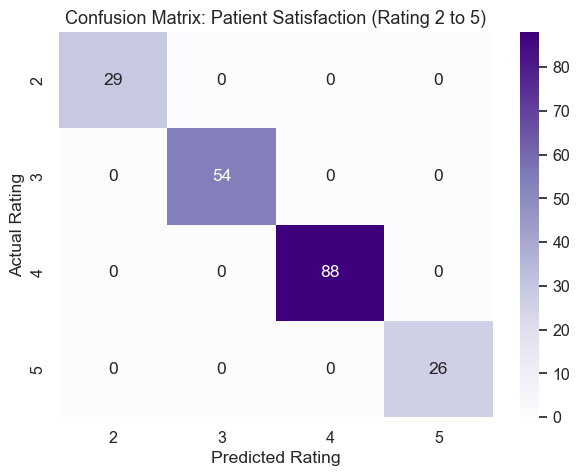

In [14]:
# Multiclass Classification for Satisfaction
pipe_clf_sat = Pipeline(steps=[
    ('prep', preprocessor_sat),
    ('model', RandomForestClassifier(n_estimators=100, random_state=42))
])

pipe_clf_sat.fit(X_train_s, y_train_s)
y_pred_sat_clf = pipe_clf_sat.predict(X_test_s)

print("=== MULTICLASS CLASSIFICATION FOR SATISFACTION (RANDOM FOREST) ===")
print(f"Accuracy: {accuracy_score(y_test_s, y_pred_sat_clf):.4f}")
print("\nClassification Report:")
print(classification_report(y_test_s, y_pred_sat_clf, digits=4))

# Multiclass Confusion Matrix
cm_sat = confusion_matrix(y_test_s, y_pred_sat_clf)
plt.figure(figsize=(7, 5))
sns.heatmap(cm_sat, annot=True, fmt='d', cmap='Purples',
            xticklabels=sorted(y_sat.unique()), yticklabels=sorted(y_sat.unique()))
plt.title('Confusion Matrix: Patient Satisfaction (Rating 2 to 5)', fontsize=13)
plt.xlabel('Predicted Rating')
plt.ylabel('Actual Rating')
plt.show()

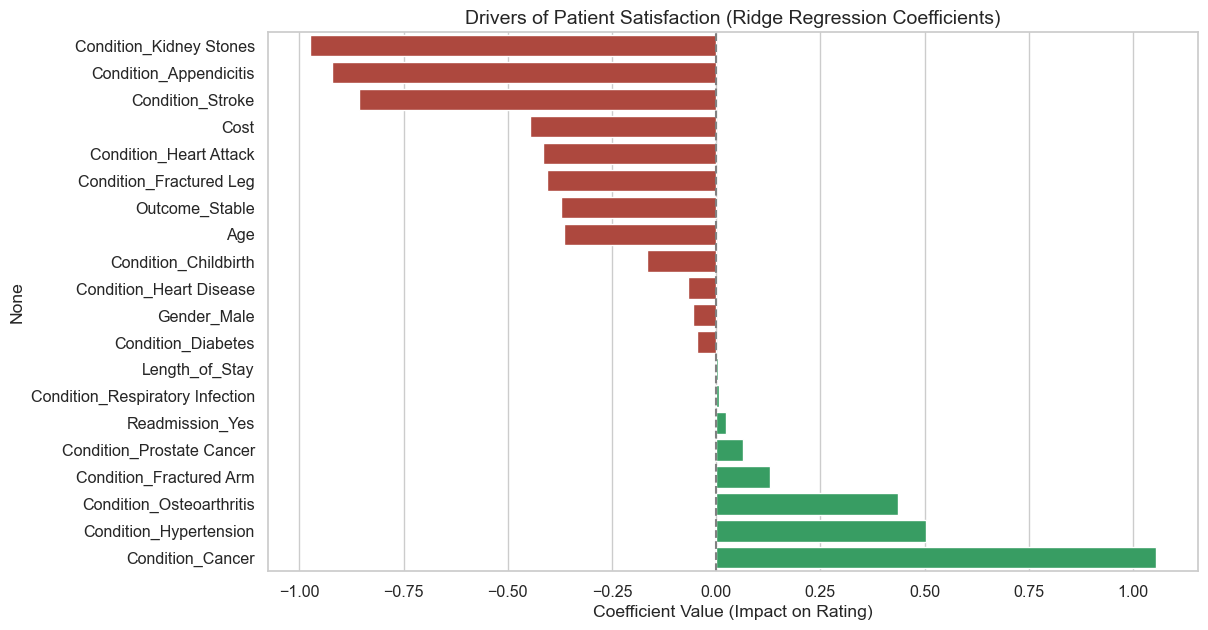

In [15]:
# Factors Influencing Patient Satisfaction (Ridge Regression Coefficients)
ridge_pipe = Pipeline(steps=[('prep', preprocessor_sat), ('model', Ridge())])
ridge_pipe.fit(X_train_s, y_train_s)

cat_encoded_sat = preprocessor_sat.named_transformers_['cat'].get_feature_names_out(cat_features_s)
all_features_sat = num_features_s + list(cat_encoded_sat)
coefficients = pd.Series(ridge_pipe.named_steps['model'].coef_, index=all_features_sat).sort_values()

plt.figure(figsize=(12, 7))
colors = ['#c0392b' if x < 0 else '#27ae60' for x in coefficients.values]
sns.barplot(x=coefficients.values, y=coefficients.index, palette=colors)
plt.title('Drivers of Patient Satisfaction (Ridge Regression Coefficients)', fontsize=14)
plt.xlabel('Coefficient Value (Impact on Rating)')
plt.axvline(0, color='gray', linestyle='--')
plt.show()

--- 
## 7. Strategic Clinical & Operational Recommendations

### 1. Readmission Prevention Program:
- **High-Risk Cohorts**: Heart Attack (100% readmission rate), Heart Disease (98.5% readmission rate), Stroke (50%), and Appendicitis (50%).
- **Intervention**: Establish dedicated post-discharge telehealth follow-ups within 48-72 hours for cardiology and neurology discharges.

### 2. Enhancing Patient Experience & Satisfaction:
- **Elderly Patient Care**: Older age correlates strongly with lower satisfaction (coefficients highlight age as the strongest negative drag).
- **Cost Transparency**: High treatment costs significantly depress patient ratings. Providing upfront financial counseling and itemized billing explanations will materially reduce patient distress.
- **Discharge Coordination**: Readmitted patients report significantly lower ratings (rating 2 predominance). Improving discharge education and medication reconciliation will directly boost overall hospital scores.